# Task 6 SVM explained with Kernel SHAP

This notebook follows the supplied `03_shap.py` workflow and the senior's Kernel SHAP example: prepare the stroke data, train a different classifier, evaluate it, and explain local and global predictions.

The alternative model is a standard RBF support vector machine with `probability=True`. There is no hyperparameter search or separate calibration wrapper. The earlier Random Forest is compared using the saved Task 2 results in `reference/`; Tasks 1–5 are not retrained or changed.

Run all cells from top to bottom. Outputs are saved in `output/task6/`.


In [1]:
from pathlib import Path
import json
import sys
import time
import warnings
from datetime import datetime
from zoneinfo import ZoneInfo
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

SEED = 2021
np.random.seed(SEED)
ROOT = Path.cwd()
if not (ROOT / "data/healthcare-dataset-stroke-data.csv").exists():
    ROOT = ROOT / "XAI_Assign1_Submission_Benjy"
OUT = ROOT / "output/task6"
OUT.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT))
from utils import DataLoader


## 1 Load and preprocess the data

Use the adapted `DataLoader` in `utils.py`, shared with Task 2. `load_dataset()` reads the CSV; `get_data_split(stratify=True, random_state=2021)` creates the raw 80:20 split. `preprocess_split()` fits the training BMI median, one-hot encodes categories and aligns the test columns. `oversample(random_state=2021)` duplicates minority training records only.

These calls preserve the previous inline calculations and the same 21 predictors. The original zero-filled `preprocess_data()` method is reserved for the Task 1 demonstration and is not called here. Restart the kernel after updating `utils.py`, then run all cells from top to bottom.


In [2]:
data_loader = DataLoader()
data_loader.load_dataset(ROOT / "data/healthcare-dataset-stroke-data.csv")
data = data_loader.data

# Use the same adapted helper and settings as Task 2.
X_train, X_test, y_train, y_test = data_loader.get_data_split(
    test_size=0.20,
    random_state=SEED,
    stratify=True,
)
X_train, X_test = data_loader.preprocess_split(X_train, X_test)
bmi_median = data_loader.bmi_median
X_balanced, y_balanced = data_loader.oversample(
    X_train,
    y_train,
    random_state=SEED,
)
X_balanced = X_balanced.reset_index(drop=True)
y_balanced = y_balanced.reset_index(drop=True)

print("Original training:", X_train.shape, "| Test:", X_test.shape)
print("Training after oversampling:", X_balanced.shape)
print("Training BMI median:", bmi_median)
print("Balanced training classes:", y_balanced.value_counts().to_dict())


/Users/benjy/UM/XAI/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/benjy/UM/XAI/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(
Original training: (4088, 21) | Test: (1022, 21)
Training after oversampling: (7778, 21)
Training BMI median: 28.1
Balanced training classes: {0: 3889, 1: 3889}


## 2 Train a simple SVM

The fitted pipeline applies scaling followed by the default RBF SVM (`C=1`, `gamma="scale"`). Scaling is learned from the oversampled training set and reused at prediction time. `probability=True` enables SVC's internal probability estimation; no separate calibration model is added. For clarity, reported labels use the same fixed probability rule as the earlier forest: stroke probability > 0.5, with ties assigned to no stroke. SVC's native `predict()` labels can differ, so their disagreement count is shown rather than mixing the two rules.


In [3]:
svm = make_pipeline(
    StandardScaler(),
    SVC(probability=True, random_state=SEED),
)
svm.fit(X_balanced, y_balanced)
stroke_class = int(np.flatnonzero(svm.classes_ == 1)[0])
probabilities = svm.predict_proba(X_test)[:, stroke_class]
predictions = (probabilities > 0.5).astype(int)
native_predictions = svm.predict(X_test)
native_disagreements = int(np.sum(native_predictions != predictions))
print("Native SVC labels differing from the probability rule:", native_disagreements)


Native SVC labels differing from the probability rule: 34


## 3 Evaluate and compare with Task 2

All 1,022 held-out records are evaluated. The reference predictions are from the existing Task 2 Random Forest. Check the test indices and labels before comparing results. Macro F1 averages both classes; stroke F1 describes the positive class only.


In [4]:
def evaluate(actual, predicted, scores):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro"),
        "Stroke precision": precision_score(actual, predicted, zero_division=0),
        "Stroke recall": recall_score(actual, predicted),
        "Stroke F1": f1_score(actual, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(actual, scores),
        "Average precision": average_precision_score(actual, scores),
    }


reference = pd.read_csv(ROOT / "reference/task2_predictions.csv")
assert np.array_equal(reference["dataset_index"], X_test.index)
assert np.array_equal(reference["actual"], y_test)

svm_metrics = evaluate(y_test, predictions, probabilities)
rf_metrics = evaluate(
    reference["actual"], reference["predicted"], reference["stroke_probability"]
)
comparison = pd.DataFrame({"Random Forest": rf_metrics, "SVM": svm_metrics})
display(comparison.round(4))
svm_cm = confusion_matrix(y_test, predictions)
rf_cm = confusion_matrix(reference["actual"], reference["predicted"])
print("SVM confusion matrix (rows actual, columns predicted):\n", svm_cm)
print("Random Forest confusion matrix:\n", rf_cm)

comparison.to_csv(OUT / "model_comparison.csv")
pd.DataFrame(
    {
        "dataset_index": X_test.index,
        "actual": y_test.to_numpy(),
        "predicted": predictions,
        "stroke_probability": probabilities,
    }
).to_csv(OUT / "test_predictions.csv", index=False)


SVM confusion matrix (rows actual, columns predicted):
 [[774 198]
 [ 22  28]]
Random Forest confusion matrix:
 [[960  12]
 [ 47   3]]


,Random Forest,SVM
Accuracy,0.9423,0.7847
Balanced accuracy,0.5238,0.6781
Macro F1,0.5312,0.5392
Stroke precision,0.2000,0.1239
Stroke recall,0.0600,0.5600
Stroke F1,0.0923,0.2029
ROC AUC,0.8279,0.7925
Average precision,0.1500,0.1634


## 4 Create Kernel SHAP explanations

Kernel SHAP calls the entire fitted SVM pipeline, including scaling, and explains **P(stroke = 1)**. Positive SHAP values raise this output relative to the background; negative values lower it.

Use 50 actual oversampled training records as background (seed 2021). The background therefore reflects the balanced training population, not the original stroke prevalence. For a manageable global analysis, explain a fixed stratified sample of 100 held-out records, including five recorded stroke cases. Explain the same local patient as Task 3 (dataset row 173) separately. Use 512 coalition samples per case, identity link, and `l1_reg=0` to retain all predictors. Independently masking category indicators can create unrealistic combinations, which limits interpretation.


In [5]:
def stroke_probability(values):
    frame = pd.DataFrame(np.asarray(values), columns=X_train.columns)
    return svm.predict_proba(frame)[:, stroke_class]


background = X_balanced.sample(n=50, random_state=SEED)
background_strokes = int(y_balanced.loc[background.index].sum())
explainer = shap.KernelExplainer(stroke_probability, background, link="identity")
base_value = float(explainer.expected_value)

positions, _ = train_test_split(
    np.arange(len(X_test)),
    train_size=100,
    stratify=y_test,
    random_state=SEED,
)
positions = np.sort(positions)
X_global = X_test.iloc[positions]
case = X_test.loc[[173]]

# Small batches make progress visible without changing which records are explained.
start = time.perf_counter()
blocks = []
with warnings.catch_warnings(record=True) as recorded_warnings:
    warnings.simplefilter("always")
    for offset in range(0, len(X_global), 10):
        np.random.seed(SEED + offset)
        blocks.append(
            explainer.shap_values(
                X_global.iloc[offset : offset + 10],
                nsamples=512,
                l1_reg=0,
                silent=True,
            )
        )
        print(
            f"Explained {min(offset + 10, len(X_global))} / {len(X_global)} records",
            flush=True,
        )
    np.random.seed(SEED)
    local_values = np.asarray(
        explainer.shap_values(
            case,
            nsamples=512,
            l1_reg=0,
            silent=True,
        )
    )[0]
shap_seconds = time.perf_counter() - start
global_values = np.concatenate(blocks)
warning_messages = sorted({str(item.message) for item in recorded_warnings})
print("Kernel SHAP runtime (seconds):", round(shap_seconds, 2))
print("Explanation warnings:", warning_messages)


Explained 10 / 100 records
Explained 20 / 100 records
Explained 30 / 100 records
Explained 40 / 100 records
Explained 50 / 100 records
Explained 60 / 100 records
Explained 70 / 100 records
Explained 80 / 100 records
Explained 90 / 100 records
Explained 100 / 100 records
Kernel SHAP runtime (seconds): 243.17
Explanation warnings: ['divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']


## 5 Check and plot the local explanation

The selected record is the same 80-year-old female with hypertension explained in Task 3. Display the actual label, predicted label, model probability and every feature contribution. Verify that the baseline plus contributions reconstructs the model output. This is a numerical consistency check, not proof of exact attributions or clinical validity.


Actual: 1 | Predicted: 1
Base: 0.525061983386627 | Probability: 0.9304155035636207
Reconstruction: 0.9304155035636206
Maximum global residual: 1.6653345369377348e-16


,feature,patient_value,shap_value
0,age,80.00,0.262439
13,work_type_Self-employed,1.00,-0.049705
1,hypertension,1.00,0.048963
17,smoking_status_Unknown,0.00,0.044194
2,heart_disease,0.00,0.028442
9,ever_married_Yes,1.00,0.024566
8,ever_married_No,0.00,0.023226
3,avg_glucose_level,91.02,-0.021436


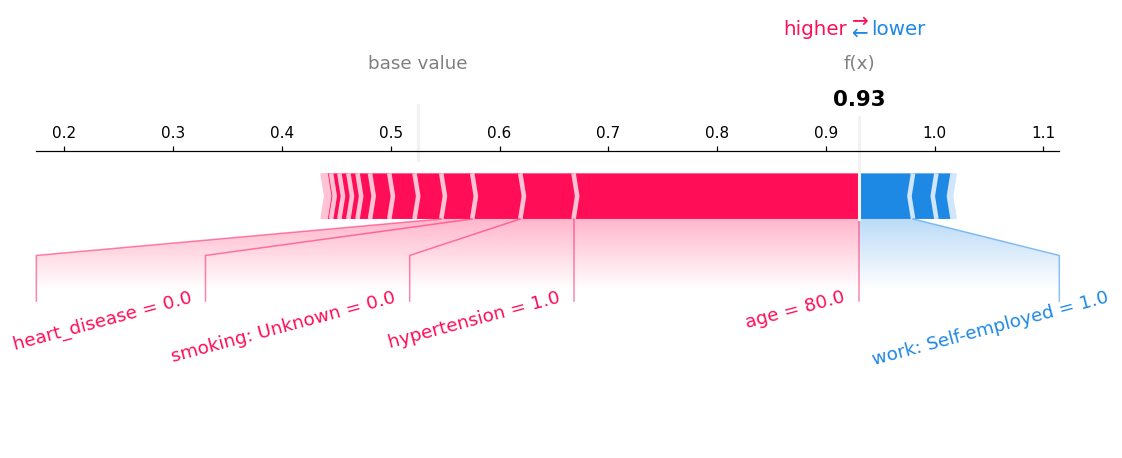

In [6]:
case_probability = float(stroke_probability(case)[0])
case_prediction = int(case_probability > 0.5)
local_residual = abs(base_value + local_values.sum() - case_probability)
global_residual = np.max(
    np.abs(base_value + global_values.sum(axis=1) - stroke_probability(X_global))
)
assert local_residual < 1e-8 and global_residual < 1e-8

contributions = pd.DataFrame(
    {
        "feature": X_test.columns,
        "patient_value": case.iloc[0].to_numpy(),
        "shap_value": local_values,
    }
).sort_values("shap_value", key=lambda values: values.abs(), ascending=False)
print("Actual:", int(y_test.loc[173]), "| Predicted:", case_prediction)
print("Base:", base_value, "| Probability:", case_probability)
print("Reconstruction:", base_value + local_values.sum())
print("Maximum global residual:", global_residual)
display(contributions.head(8))

short_names = [
    name.replace("avg_glucose_level", "glucose")
    .replace("smoking_status_", "smoking: ")
    .replace("work_type_", "work: ")
    .replace("Residence_type_", "residence: ")
    .replace("ever_married_", "married: ")
    for name in X_test.columns
]
shap.force_plot(
    base_value,
    local_values,
    case.iloc[0].to_numpy(),
    feature_names=short_names,
    matplotlib=True,
    show=False,
    figsize=(12, 3.5),
    text_rotation=15,
    contribution_threshold=0.10,
)
plt.savefig(OUT / "local_force.png", dpi=200, bbox_inches="tight")
plt.show()
shap.save_html(
    str(OUT / "local_force.html"),
    shap.force_plot(
        base_value,
        local_values,
        case.iloc[0],
        feature_names=list(X_test.columns),
    ),
)
contributions.to_csv(OUT / "local_contributions.csv", index=False)


## 6 Plot and interpret the global explanation

The beeswarm displays the top ten encoded predictors across the 100 sampled test records. Dot position is the signed probability contribution; colour represents high or low feature values. Compute the Random Forest ranking on exactly these same records using its saved Task 2 SHAP values. Its implicit oversampled tree-path reference differs from the SVM's explicit background, so compare patterns rather than treating magnitudes as a controlled model comparison.


task6_cell_13:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.


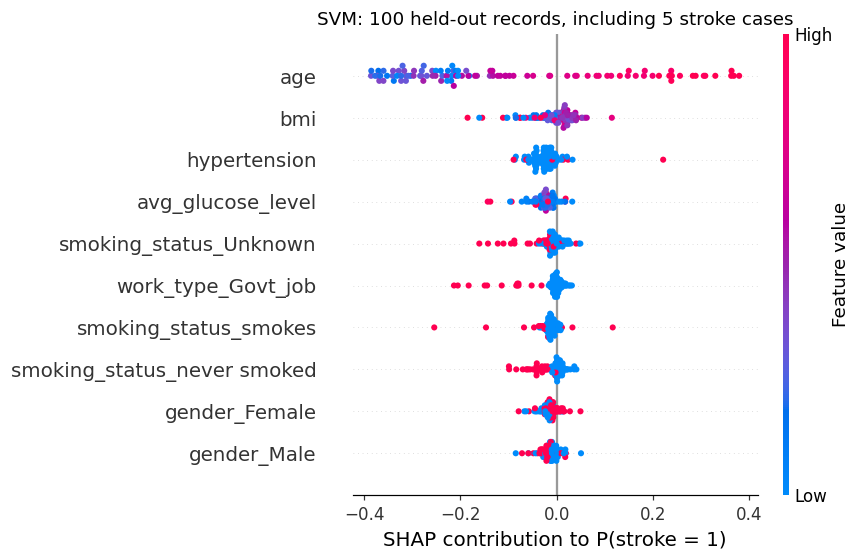

,feature,mean_absolute_shap
0,age,0.230083
4,bmi,0.034310
1,hypertension,0.029857
3,avg_glucose_level,0.028356
17,smoking_status_Unknown,0.021969


In [7]:
np.random.seed(SEED)
shap.summary_plot(
    global_values,
    X_global,
    max_display=10,
    show=False,
    plot_size=(8, 5.2),
)
plt.xlabel("SHAP contribution to P(stroke = 1)")
plt.title("SVM: 100 held-out records, including 5 stroke cases")
plt.tight_layout()
plt.savefig(OUT / "global_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

importance = pd.DataFrame(
    {
        "feature": X_test.columns,
        "mean_absolute_shap": np.abs(global_values).mean(axis=0),
    }
).sort_values("mean_absolute_shap", ascending=False)
display(importance.head(5))

rf_shap = np.load(ROOT / "reference/task2_shap.npz")
assert np.array_equal(rf_shap["dataset_indices"], X_test.index)
assert list(rf_shap["feature_names"]) == list(X_test.columns)
rf_global = rf_shap["values"][positions]
rf_importance = pd.DataFrame(
    {
        "feature": X_test.columns,
        "mean_absolute_shap": np.abs(rf_global).mean(axis=0),
    }
).sort_values("mean_absolute_shap", ascending=False)
rf_base = float(rf_shap["base_values"][0])
rf_residual = float(
    np.max(
        np.abs(
            rf_shap["base_values"][positions]
            + rf_global.sum(axis=1)
            - reference.iloc[positions]["stroke_probability"].to_numpy()
        )
    )
)
assert rf_residual < 1e-8

importance.to_csv(OUT / "global_importance.csv", index=False)
rf_importance.to_csv(OUT / "rf_matched_importance.csv", index=False)
X_global.to_csv(OUT / "global_sample.csv", index_label="dataset_index")
background.to_csv(OUT / "background.csv", index_label="oversampled_training_position")
np.savez_compressed(
    OUT / "shap_values.npz",
    values=global_values,
    local_values=local_values,
    base_value=base_value,
    data=X_global.to_numpy(),
    dataset_indices=X_global.index.to_numpy(),
    feature_names=np.array(X_test.columns, dtype=str),
)


## 7 Save a short results summary

Use the results below for Sections 7–8 of the report. A better accuracy alone does not establish better stroke detection. These scores classify recorded stroke status; they are not validated future risk estimates. The global sample is small, Kernel SHAP is approximate, and explanation stability, external validity and calibration quality were not assessed.


In [8]:
summary = {
    "data_loading": "Adapted utils.DataLoader shared with Task 2",
    "date": datetime.now(ZoneInfo("Asia/Kuala_Lumpur")).date().isoformat(),
    "seed": SEED,
    "train_records": len(X_train),
    "test_records": len(X_test),
    "test_stroke_records": int(y_test.sum()),
    "balanced_training_records": len(X_balanced),
    "bmi_median": float(bmi_median),
    "model": "StandardScaler + SVC(probability=True)",
    "C": 1.0,
    "gamma": "scale",
    "kernel": "rbf",
    "decision_rule": "P(stroke = 1) > 0.5; ties assigned to class 0",
    "native_prediction_disagreements": native_disagreements,
    "background_records": 50,
    "background_stroke_records": background_strokes,
    "global_records": len(X_global),
    "global_stroke_records": int(y_test.iloc[positions].sum()),
    "coalition_samples": 512,
    "link": "identity",
    "l1_reg": 0,
    "base_value": base_value,
    "rf_base_value": rf_base,
    "local_dataset_index": 173,
    "local_actual": int(y_test.loc[173]),
    "local_probability": case_probability,
    "local_prediction": case_prediction,
    "local_residual": float(local_residual),
    "global_residual": float(global_residual),
    "rf_residual": rf_residual,
    "shap_seconds": shap_seconds,
    "svm_metrics": svm_metrics,
    "rf_metrics": rf_metrics,
    "svm_confusion_matrix": svm_cm.tolist(),
    "rf_confusion_matrix": rf_cm.tolist(),
    "warnings": warning_messages,
    "packages": {
        name: version(name)
        for name in [
            "numpy",
            "pandas",
            "scikit-learn",
            "imbalanced-learn",
            "shap",
            "matplotlib",
        ]
    },
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))


{
  "data_loading": "Adapted utils.DataLoader shared with Task 2",
  "date": "2026-11-09",
  "seed": 2021,
  "train_records": 4088,
  "test_records": 1022,
  "test_stroke_records": 50,
  "balanced_training_records": 7778,
  "bmi_median": 28.1,
  "model": "StandardScaler + SVC(probability=True)",
  "C": 1.0,
  "gamma": "scale",
  "kernel": "rbf",
  "decision_rule": "P(stroke = 1) > 0.5; ties assigned to class 0",
  "native_prediction_disagreements": 34,
  "background_records": 50,
  "background_stroke_records": 26,
  "global_records": 100,
  "global_stroke_records": 5,
  "coalition_samples": 512,
  "link": "identity",
  "l1_reg": 0,
  "base_value": 0.525061983386627,
  "rf_base_value": 0.5004757006942662,
  "local_dataset_index": 173,
  "local_actual": 1,
  "local_probability": 0.9304155035636207,
  "local_prediction": 1,
  "local_residual": 1.1102230246251565e-16,
  "global_residual": 1.6653345369377348e-16,
  "rf_residual": 3.219646771412954e-15,
  "shap_seconds": 243.174580875,
  "sv

## Main findings from this run

- At the same 0.5 probability threshold, the SVM detects **28 of 50** stroke records versus **3 of 50** for the forest, but produces **198 false positives** versus **12**.
- Stroke F1 improves from **0.092** to **0.203**; SVM accuracy falls to **78.47%**. The preferred model depends on the cost of missed cases and false alarms.
- Row 173 is a **true positive** for this SVM at probability **0.9304**, whereas the forest classified it incorrectly at **0.23**.
- These probabilities reflect models fitted on oversampled training data. They are not established population probabilities or future stroke-risk estimates.
- Kernel SHAP emitted numerical matrix-multiplication warnings. All saved values are finite and reconstruct the predictions within tolerance; this does not establish attribution accuracy or stability.


## Sources

- Supplied `xai-series-master/03_shap.py` and `utils.py`: workflow for loading, splitting, training-only oversampling and SHAP plots.
- Senior's `06_kernel_shap.py`: SVC with probability estimates and KernelExplainer. Adaptations: scaling, training-median BMI, the existing stratified split, correct scalar class-1 output, and matching explanation rows for the global plot.
- [SVC documentation](https://scikit-learn.org/1.6/modules/generated/sklearn.svm.SVC.html).
- [KernelExplainer documentation](https://shap.readthedocs.io/en/stable/generated/shap.KernelExplainer.html).
